What are the most demanded skills for the top 3 most popular data roles?

Methodology

1. Clean-up skill column
2. Calculate skill count based on job title
3. Calculate skill percentage
4. Plot final findings

In [1]:
# Importing Libraries
import ast
import seaborn as sns
import pandas as pd
from datasets import load_dataset 
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply( lambda x: ast.literal_eval (x) if pd.notna(x) else (x) )

c:\Users\NAFIZUR RAHAMAN\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_US = df[df['job_country'] == 'United States'].copy()

In [3]:
df_skills = df_US.explode('job_skills')

df_skills[['job_title', 'job_skills']]

,job_title,job_skills
0,Senior Clinical Data Engineer / Principal Clin...,NaN
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,python
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,c++
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,java
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,matlab
...,...,...
785692,Data Scientist- Hybrid Work Location,r
785703,Data Analyst - CRYPTOGRAPHY - Full-time,NaN
785705,Expert Business Data Analyst - Now Hiring,sql
785705,Expert Business Data Analyst - Now Hiring,python


In [6]:
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

df_skills_count = df_skills_count.reset_index(name='skill_count')

df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [16]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

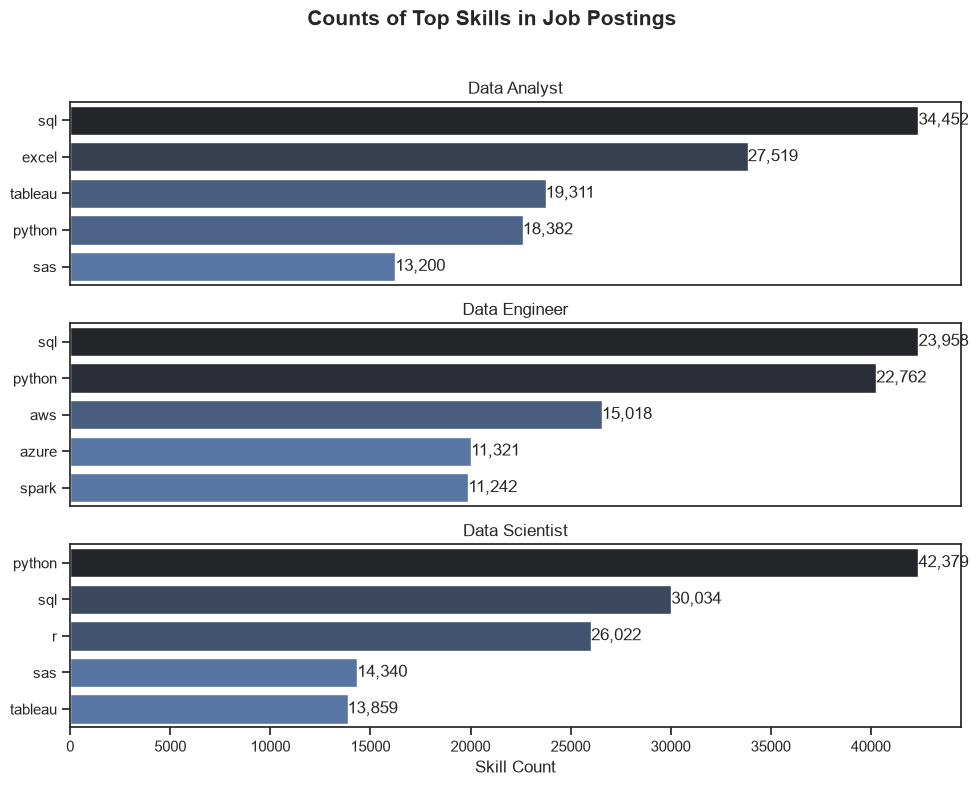

In [40]:
fig, ax = plt.subplots(
    len(job_titles),
    1,
    figsize=(10, 8)
)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):

    df_plot = (
        df_skills_count[
            df_skills_count['job_title_short'] == job_title
        ]
        .head(5)
    )

    sns.barplot(
        data=df_plot,
        x='skill_count',
        y='job_skills',
        ax=ax[i],
        hue='skill_count',
        palette='dark:b_r'
    )

    # remove legend
    ax[i].get_legend().remove()

    # formatting
    ax[i].set_title(job_title, fontsize=12)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')

    # add values at end of bars
    for n, v in enumerate(df_plot['skill_count']):
        ax[i].text(
            v + 1,
            n,
            f'{v:,.0f}',
            va='center'
        )

    # hide x-axis labels except bottom chart
    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

# bottom chart only
ax[-1].set_xlabel('Skill Count')

fig.suptitle(
    'Counts of Top Skills in Job Postings',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

In [21]:
df_job_title_count = df_US['job_title_short'].value_counts().reset_index(name='jobs_total')

In [22]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how='left', on='job_title_short')

df_skills_perc['skill_percent'] = 100*df_skills_perc['skill_count'] / df_skills_perc['jobs_total']

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


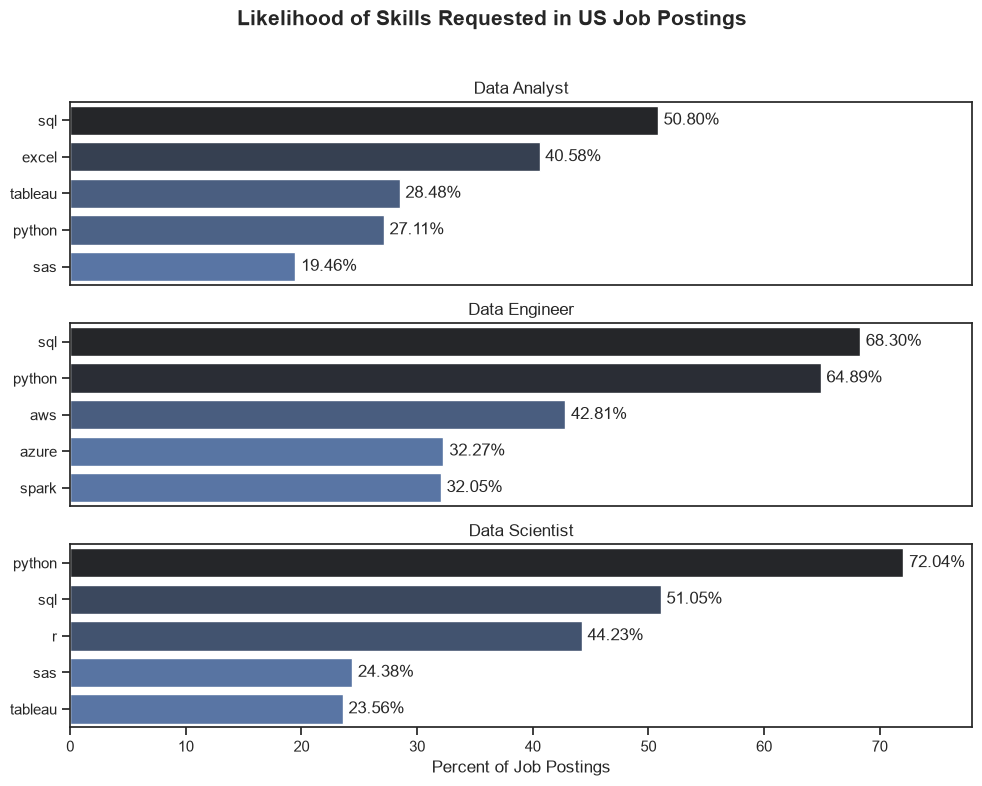

In [39]:
fig, ax = plt.subplots(
    len(job_titles),
    1,
    figsize=(10, 8)
)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):

    df_plot = (
        df_skills_perc[
            df_skills_perc['job_title_short'] == job_title
        ]
        .sort_values('skill_percent', ascending=False)
        .head(5)
    )

    sns.barplot(
        data=df_plot,
        x='skill_percent',
        y='job_skills',
        ax=ax[i],
        hue='skill_count',
        palette='dark:b_r'
    )

    # Remove legend
    ax[i].get_legend().remove()

    # Titles and labels
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')

    # Common x-axis
    ax[i].set_xlim(0, 78)

    # Add data labels
    for n, v in enumerate(df_plot['skill_percent']):
        ax[i].text(
            v + 0.5,
            n,
            f'{v:.2f}%',
            va='center'
        )

    # Hide x-axis ticks except bottom chart
    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

# Bottom chart x label
ax[-1].set_xlabel('Percent of Job Postings')

# Main Title
fig.suptitle(
    'Likelihood of Skills Requested in US Job Postings',
    fontsize=15,
    weight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

In [28]:
print(df_skills_count.columns.tolist())

['job_skills', 'job_title_short', 'skill_count']
